In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set chart style
sns.set_style("whitegrid")

# Load dataset
df = pd.read_csv("DataCoSupplyChainDataset.csv", encoding="latin1")

# View data
print(df.shape)
df.head()

(180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [2]:
# Dataset information
df.info()

# Statistical summary
df.describe()

# Check missing values
print(df.isnull().sum().sort_values(ascending=False))

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check unique orders
print("Total orders:", df["Order Id"].nunique())

# Check unique order items
print("Total order items:", df["Order Item Id"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [3]:
# Check duplicate order item IDs
print("Duplicate Order Item IDs:",
      df["Order Item Id"].duplicated().sum())

# Check delivery status
print(df["Delivery Status"].value_counts())

# Check order status
print(df["Order Status"].value_counts())

# Check columns with more than 50% missing values
missing = df.isnull().mean() * 100

print(missing[missing > 50])

Duplicate Order Item IDs: 0
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64
Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64
Order Zipcode           86.239676
Product Description    100.000000
dtype: float64


In [4]:
# Convert date columns into datetime format

df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"]
)

df["shipping date (DateOrders)"] = pd.to_datetime(
    df["shipping date (DateOrders)"]
)

# Calculate shipping duration using dates

df["Calendar_Days"] = (
    df["shipping date (DateOrders)"] -
    df["order date (DateOrders)"]
).dt.days

# Compare with actual shipping days

df["Date_Check"] = (
    df["Calendar_Days"] -
    df["Days for shipping (real)"]
)

print("Rows with date differences:",
      (df["Date_Check"] != 0).sum())

Rows with date differences: 4657


In [5]:
# Remove canceled shipments and invalid durations

delivery_data = df[
    (df["Delivery Status"] != "Shipping canceled") &
    (df["Days for shipping (real)"] >= 0) &
    (df["Days for shipment (scheduled)"] >= 0)
].copy()

print("Original rows:", len(df))
print("Delivery rows:", len(delivery_data))
print("Unique orders:", delivery_data["Order Id"].nunique())

Original rows: 180519
Delivery rows: 172765
Unique orders: 62897


In [7]:
# Calculate delay days

delivery_data["Delay_Days"] = (
    delivery_data["Days for shipping (real)"] -
    delivery_data["Days for shipment (scheduled)"]
)

# Identify delayed orders

delivery_data["Is_Delayed"] = (
    delivery_data["Delay_Days"] > 0
)

# Classify delivery performance

delivery_data["Delivery_Performance"] = np.where(
    delivery_data["Delay_Days"] > 0,
    "Late",
    np.where(
        delivery_data["Delay_Days"] == 0,
        "On Time",
        "Early"
    )
)

In [8]:
# Create an order-level dataset

orders = delivery_data.groupby("Order Id").agg(
    Actual_Days=("Days for shipping (real)", "first"),
    Scheduled_Days=("Days for shipment (scheduled)", "first"),
    Delay_Days=("Delay_Days", "first"),
    Delivery_Performance=("Delivery_Performance", "first")
).reset_index()

# Count delivery performance

print(orders["Delivery_Performance"].value_counts())

# Calculate late delivery percentage

late_orders = (orders["Delivery_Performance"] == "Late").sum()

total_orders = len(orders)

late_rate = (late_orders / total_orders) * 100

print("Total orders:", total_orders)
print("Late orders:", late_orders)
print("Late delivery rate:", round(late_rate, 2), "%")

print("Average delay:",
      round(orders["Delay_Days"].mean(), 2), "days")

Delivery_Performance
Late       36048
Early      15127
On Time    11722
Name: count, dtype: int64
Total orders: 62897
Late orders: 36048
Late delivery rate: 57.31 %
Average delay: 0.57 days


In [9]:
# Classify delay severity

orders["Delay_Severity"] = np.where(
    orders["Delay_Days"] < 0, "Early",
    np.where(
        orders["Delay_Days"] == 0, "On Time",
        np.where(
            orders["Delay_Days"] <= 2,
            "1-2 Days Late",
            "3+ Days Late"
        )
    )
)

# Count each category

print(orders["Delay_Severity"].value_counts())

# Calculate percentages

print(
    orders["Delay_Severity"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Delay_Severity
1-2 Days Late    31140
Early            15127
On Time          11722
3+ Days Late      4908
Name: count, dtype: int64
Delay_Severity
1-2 Days Late    49.51
Early            24.05
On Time          18.64
3+ Days Late      7.80
Name: proportion, dtype: float64


In [10]:
# Create shipping mode summary

shipping = delivery_data.groupby("Order Id").agg(
    Shipping_Mode=("Shipping Mode", "first"),
    Delay_Days=("Delay_Days", "first"),
    Actual_Days=("Days for shipping (real)", "first"),
    Scheduled_Days=("Days for shipment (scheduled)", "first")
).reset_index()

# Group by shipping mode

shipping_summary = shipping.groupby("Shipping_Mode").agg(
    Orders=("Order Id", "nunique"),
    Average_Actual_Days=("Actual_Days", "mean"),
    Average_Scheduled_Days=("Scheduled_Days", "mean"),
    Average_Delay=("Delay_Days", "mean"),
    Late_Rate=("Delay_Days", lambda x: (x > 0).mean() * 100)
).round(2)

print(shipping_summary)

                Orders  Average_Actual_Days  Average_Scheduled_Days  \
Shipping_Mode                                                         
First Class       9602                 2.00                     1.0   
Same Day          3407                 0.48                     0.0   
Second Class     12256                 4.00                     2.0   
Standard Class   37632                 3.99                     4.0   

                Average_Delay  Late_Rate  
Shipping_Mode                             
First Class              1.00     100.00  
Same Day                 0.48      48.37  
Second Class             2.00      79.99  
Standard Class          -0.01      39.85  


In [11]:
# Market analysis

market = delivery_data.groupby("Order Id").agg(
    Market=("Market", "first"),
    Delay_Days=("Delay_Days", "first")
).reset_index()

market_summary = market.groupby("Market").agg(
    Orders=("Order Id", "nunique"),
    Late_Rate=("Delay_Days", lambda x: (x > 0).mean() * 100),
    Average_Delay=("Delay_Days", "mean")
).round(2)

print(market_summary.sort_values("Late_Rate", ascending=False))


# Region analysis

region = delivery_data.groupby("Order Id").agg(
    Region=("Order Region", "first"),
    Delay_Days=("Delay_Days", "first")
).reset_index()

region_summary = region.groupby("Region").agg(
    Orders=("Order Id", "nunique"),
    Late_Rate=("Delay_Days", lambda x: (x > 0).mean() * 100),
    Average_Delay=("Delay_Days", "mean")
).round(2)

print(region_summary.sort_values("Late_Rate", ascending=False))

              Orders  Late_Rate  Average_Delay
Market                                        
Pacific Asia   16853      57.68           0.58
USCA            8178      57.52           0.58
Europe         17763      57.42           0.56
LATAM          16414      56.90           0.55
Africa          3689      56.55           0.55
                 Orders  Late_Rate  Average_Delay
Region                                           
Central Africa      533      60.04           0.63
East Africa         589      59.08           0.59
South of  USA      1280      58.83           0.62
West Asia          1935      58.50           0.59
Western Europe     9563      58.40           0.59
Eastern Europe     1246      58.03           0.59
Southeast Asia     4173      58.02           0.57
South Asia         3219      57.94           0.59
US Center          1852      57.83           0.58
East of USA        2219      57.50           0.58
Eastern Asia       3171      57.33           0.57
Central America    90

In [12]:
# Keep one record per order and category

category = delivery_data[
    ["Order Id", "Category Name", "Delay_Days"]
].drop_duplicates(
    ["Order Id", "Category Name"]
)

# Group by product category

category_summary = category.groupby("Category Name").agg(
    Orders=("Order Id", "nunique"),
    Late_Rate=("Delay_Days", lambda x: (x > 0).mean() * 100),
    Average_Delay=("Delay_Days", "mean")
).round(2)

print(category_summary.sort_values("Late_Rate", ascending=False))

                      Orders  Late_Rate  Average_Delay
Category Name                                         
Golf Bags & Carts         61      68.85           0.77
Lacrosse                 327      62.69           0.66
Pet Supplies             472      61.44           0.70
Cameras                  562      61.21           0.62
Accessories             1670      59.82           0.60
Music                    417      59.47           0.58
Boxing & MMA             400      59.25           0.66
Fitness Accessories      294      59.18           0.62
Crafts                   458      59.17           0.62
As Seen on  TV!           66      59.09           0.70
Sporting Goods           336      58.93           0.60
Strength Training        109      58.72           0.64
Books                    391      58.57           0.57
Golf Gloves             1023      58.46           0.61
Girls' Apparel          1128      58.42           0.58
Electronics             2931      58.38           0.58
Health and

In [13]:
# Create monthly order data

monthly = delivery_data.groupby("Order Id").agg(
    Order_Date=("order date (DateOrders)", "first"),
    Delay_Days=("Delay_Days", "first")
).reset_index()

# Extract month

monthly["Month"] = monthly["Order_Date"].dt.to_period("M")

# Calculate monthly late delivery rate

monthly_summary = monthly.groupby("Month").agg(
    Orders=("Order Id", "nunique"),
    Late_Rate=("Delay_Days", lambda x: (x > 0).mean() * 100)
).reset_index()

print(monthly_summary.round(2))

      Month  Orders  Late_Rate
0   2015-01    1713      56.22
1   2015-02    1505      57.87
2   2015-03    1702      57.46
3   2015-04    1639      56.56
4   2015-05    1684      57.54
5   2015-06    1651      57.00
6   2015-07    1704      56.51
7   2015-08    1678      57.57
8   2015-09    1634      58.20
9   2015-10    1696      57.37
10  2015-11    1658      56.76
11  2015-12    1731      57.08
12  2016-01    1703      58.60
13  2016-02    1574      56.73
14  2016-03    1700      58.06
15  2016-04    1630      56.75
16  2016-05    1675      57.97
17  2016-06    1617      59.86
18  2016-07    1662      55.48
19  2016-08    1698      57.89
20  2016-09    1664      57.03
21  2016-10    1703      57.31
22  2016-11    1639      57.05
23  2016-12    1690      58.58
24  2017-01    1685      55.79
25  2017-02    1538      57.15
26  2017-03    1710      57.54
27  2017-04    1666      55.04
28  2017-05    1672      57.72
29  2017-06    1605      56.76
30  2017-07    1693      57.06
31  2017

In [14]:
# Calculate profit using the ratio

delivery_data["Calculated_Profit"] = (
    delivery_data["Order Item Total"] *
    delivery_data["Order Item Profit Ratio"]
)

# Compare calculated and recorded profit

delivery_data["Profit_Difference"] = (
    delivery_data["Order Profit Per Order"] -
    delivery_data["Calculated_Profit"]
)

# Count matching rows

matching = (
    delivery_data["Profit_Difference"].abs() <= 0.02
).sum()

print("Matching rows:", matching)

print("Mismatching rows:",
      len(delivery_data) - matching)

Matching rows: 110508
Mismatching rows: 62257


In [15]:
# Calculate total profit and order value

profit = delivery_data.groupby("Order Id").agg(
    Total_Profit=("Order Profit Per Order", "sum"),
    Order_Value=("Order Item Total", "sum"),
    Delay_Days=("Delay_Days", "first")
).reset_index()

# Calculate profit margin

profit["Profit_Margin"] = (
    profit["Total_Profit"] / profit["Order_Value"]
) * 100

# Classify delivery performance

profit["Delivery_Performance"] = np.where(
    profit["Delay_Days"] > 0, "Late",
    np.where(
        profit["Delay_Days"] == 0, "On Time", "Early"
    )
)

# Compare profitability

profit_summary = profit.groupby("Delivery_Performance").agg(
    Orders=("Order Id", "nunique"),
    Average_Order_Value=("Order_Value", "mean"),
    Average_Profit=("Total_Profit", "mean"),
    Median_Profit=("Total_Profit", "median"),
    Average_Profit_Margin=("Profit_Margin", "mean"),
    Median_Profit_Margin=("Profit_Margin", "median")
).round(2)

print(profit_summary)

# Overall weighted profit margin

overall_margin = (
    profit["Total_Profit"].sum() /
    profit["Order_Value"].sum()
) * 100

print("Overall profit margin:", round(overall_margin, 2), "%")

                      Orders  Average_Order_Value  Average_Profit  \
Delivery_Performance                                                
Early                  15127               506.14           61.82   
Late                   36048               501.62           59.37   
On Time                11722               503.82           62.37   

                      Median_Profit  Average_Profit_Margin  \
Delivery_Performance                                         
Early                         72.44                  12.36   
Late                          72.60                  11.88   
On Time                       73.28                  12.31   

                      Median_Profit_Margin  
Delivery_Performance                        
Early                                22.73  
Late                                 22.77  
On Time                              23.11  
Overall profit margin: 12.03 %


               Total_Profit  Order_Value  Profit_Margin  Delay_Days
Total_Profit           1.00          0.2           0.78       -0.01
Order_Value            0.20          1.0          -0.00       -0.00
Profit_Margin          0.78         -0.0           1.00       -0.01
Delay_Days            -0.01         -0.0          -0.01        1.00


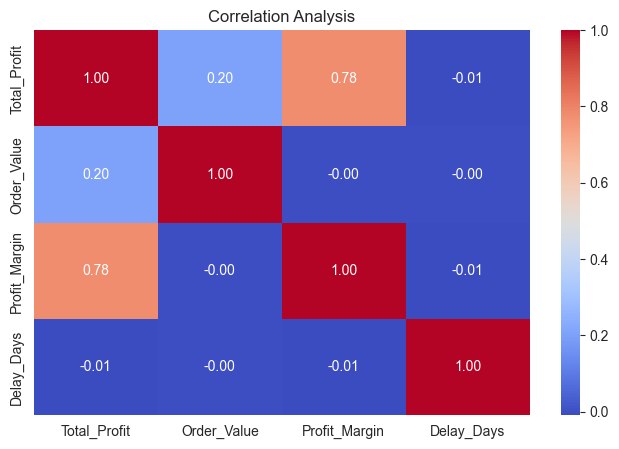

In [16]:
# Select numerical columns

correlation = profit[
    ["Total_Profit", "Order_Value", "Profit_Margin", "Delay_Days"]
].corr()

print(correlation.round(2))

# Display heatmap

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Analysis")

plt.show()

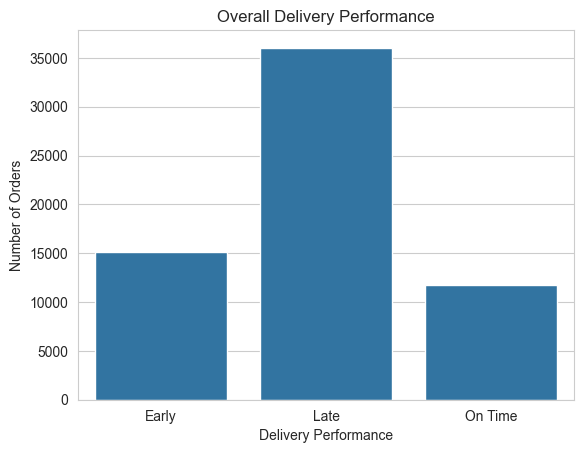

In [17]:
sns.countplot(data=orders, x="Delivery_Performance")

plt.title("Overall Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Number of Orders")

plt.show()

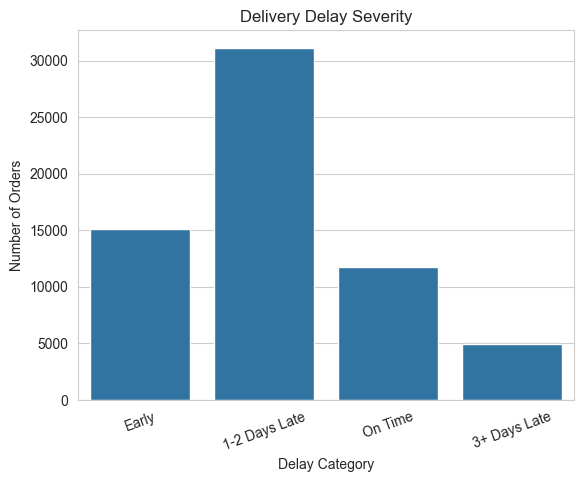

In [18]:
sns.countplot(data=orders, x="Delay_Severity")

plt.title("Delivery Delay Severity")
plt.xlabel("Delay Category")
plt.ylabel("Number of Orders")

plt.xticks(rotation=20)
plt.show()

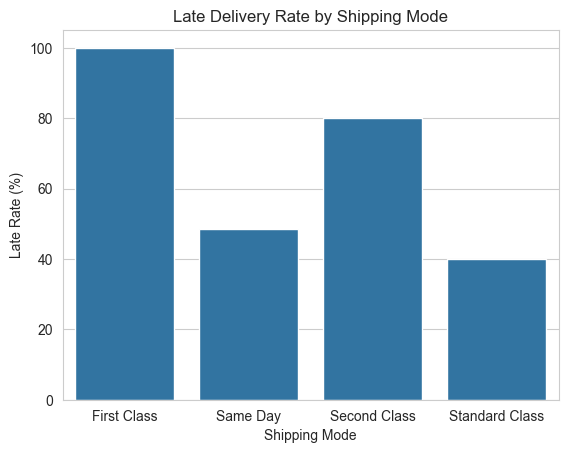

In [19]:
sns.barplot(
    data=shipping_summary.reset_index(),
    x="Shipping_Mode",
    y="Late_Rate"
)

plt.title("Late Delivery Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Late Rate (%)")

plt.show()

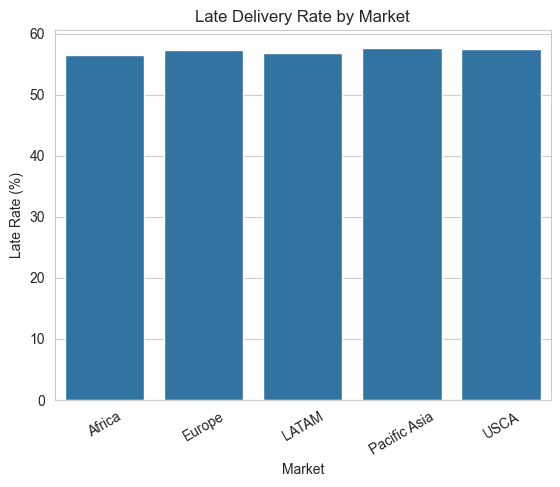

In [20]:
sns.barplot(
    data=market_summary.reset_index(),
    x="Market",
    y="Late_Rate"
)

plt.title("Late Delivery Rate by Market")
plt.xlabel("Market")
plt.ylabel("Late Rate (%)")

plt.xticks(rotation=30)
plt.show()

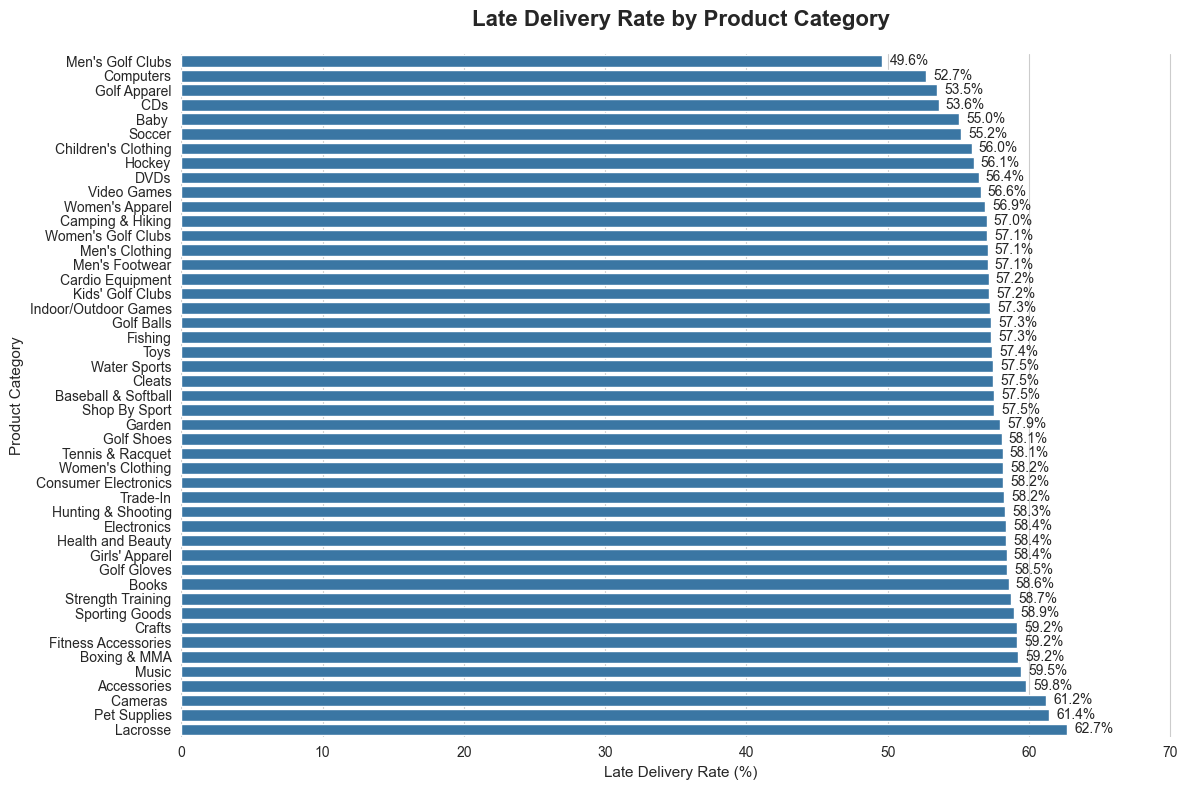

In [26]:
# Select categories with at least 100 orders

category_chart = category_summary[
    category_summary["Orders"] >= 100
].reset_index()

# Sort from highest to lowest late rate

category_chart = category_chart.sort_values(
    "Late_Rate", ascending=True
)

# Create chart

plt.figure(figsize=(12, 8))

sns.barplot(
    data=category_chart,
    x="Late_Rate",
    y="Category Name",
    color="#2878B5"
)

# Add percentage labels

for i, value in enumerate(category_chart["Late_Rate"]):
    plt.text(
        value + 0.5,
        i,
        f"{value:.1f}%",
        va="center"
    )

# Chart formatting

plt.title(
    "Late Delivery Rate by Product Category",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Late Delivery Rate (%)", fontsize=11)
plt.ylabel("Product Category", fontsize=11)

plt.xlim(0, category_chart["Late_Rate"].max() + 8)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

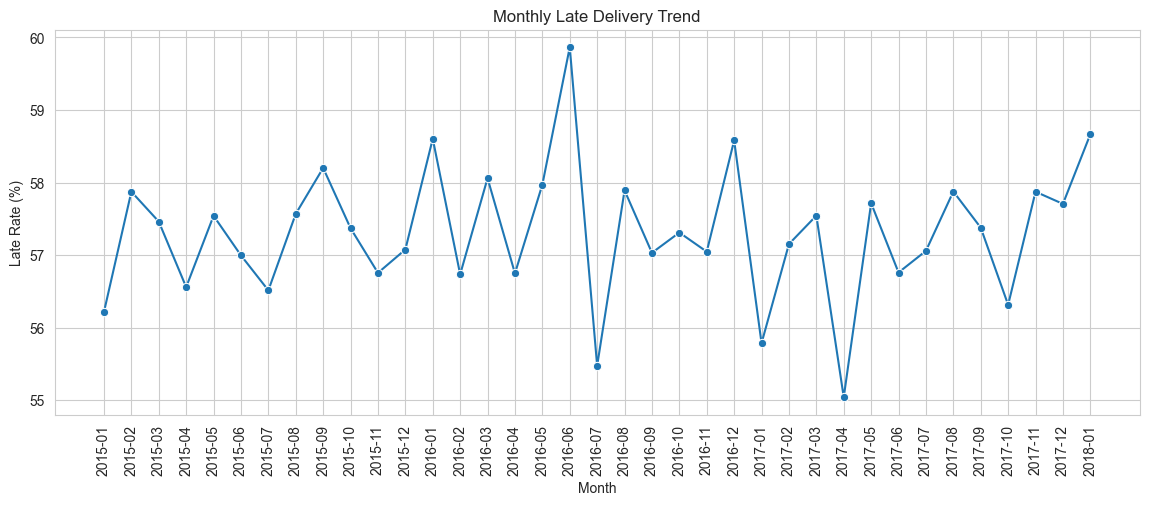

In [22]:
monthly_summary["Month"] = monthly_summary["Month"].astype(str)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_summary,
    x="Month",
    y="Late_Rate",
    marker="o"
)

plt.title("Monthly Late Delivery Trend")
plt.xlabel("Month")
plt.ylabel("Late Rate (%)")

plt.xticks(rotation=90)
plt.show()

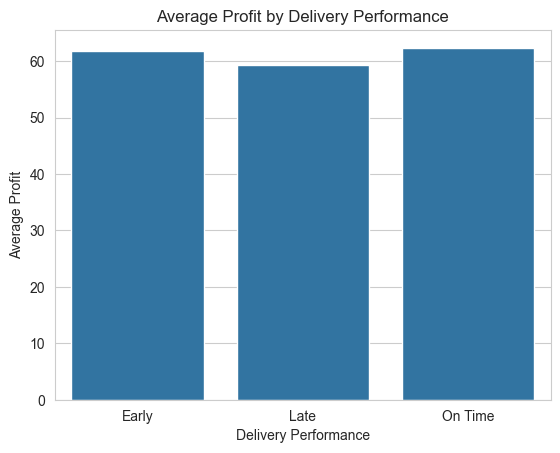

In [23]:
sns.barplot(
    data=profit_summary.reset_index(),
    x="Delivery_Performance",
    y="Average_Profit"
)

plt.title("Average Profit by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Average Profit")

plt.show()

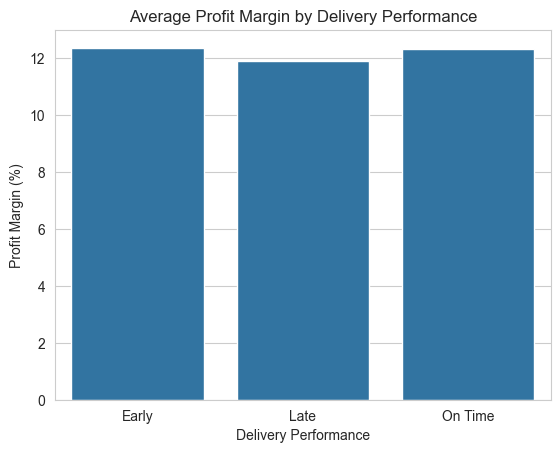

In [24]:
sns.barplot(
    data=profit_summary.reset_index(),
    x="Delivery_Performance",
    y="Average_Profit_Margin"
)

plt.title("Average Profit Margin by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Profit Margin (%)")

plt.show()

In [25]:
# Save important summary tables

shipping_summary.to_csv("shipping_analysis.csv")
market_summary.to_csv("market_analysis.csv")
region_summary.to_csv("region_analysis.csv")
category_summary.to_csv("category_analysis.csv")
monthly_summary.to_csv("monthly_analysis.csv", index=False)
profit_summary.to_csv("profitability_analysis.csv")

print("All analysis files saved successfully!")

All analysis files saved successfully!
